In [20]:
%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')

import sys
sys.path.insert(0, "../../")

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


Running query in 'duckdb:///:memory:'

## Individual Life Data Modeling

Generalized Linear Models are powerful because they afford the modeler tremendous control. They are also challenging to get right for the same reasons.  Using a standard GLM (e.g. R's `glm()` function or `GLM()` from [statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html#statsmodels.genmod.generalized_linear_model.GLM)) **is risky** with large datasets.  Instead, we need to use a regularized GLM, like `glmnet` or `glum`.

To know how to build a good GLM on any size dataset, you first need to understand the **design matrix**.

### Design Matrix Explained

Suppose we want to fit the variables age and sex.  The data looks something like this:

| Age          | Gender       |  Expected Claims| Actual Claims| 
|--------------|--------------|-----------------|--------------|             
| 40           | male         |   10            |  14          | 
| 42           | female       |   7             |  3           |

Conceptually, we want to fit 3 coefficients ($\beta$'s) so that:

$$
    x = \beta_0 + \text{age} * \beta_1 + \text{gender} * \beta_2 = \text{actual claims}
$$

The desired output is a **rate** (poisson / tweedie), e.g. a mortality ($q_x$) so that:

$$
    \text{exposures} \times q_x = \text{actual claims}
$$

We need to use a little algebra to write the above as a GLM.  We define our model as:

$$
    \text{exposures} \times q_x = \exp{\big[ \log{(\text{exposures}) + x }} \big] = \text{actual claims}
$$

We can define the same model using linear algebra / matrix notation.  

$$
    \exp \big[\log{(\text{exposures})} + X \beta \big] = \text{predicted count} = \text{actual count}
$$

**X is the design matrix.**  For our simple model, it looks like this:

| Intercept    | Age          | Gender_MALE| 
|--------------|--------------|------------|             
|  1           | 40           |     1      |
|  1           | 42           |     0      |

When we matrix multiply it by the vector of $\beta's$

| Beta        |
|-------------|
| $ \beta_0 $ |
| $ \beta_1 $ |
| $ \beta_2 $ |

We get

| log prediction |
|----------------|
| $\beta_0 + \text{40} * \beta_1 + \text{1} * \beta_2$|
| $\beta_0 + \text{42} * \beta_1 + \text{0} * \beta_2$|

### Building a design matrix in Python

In [21]:
import formulaic as frm, pandas as pd, numpy as np

df_data = pd.DataFrame({
    "age" : np.random.randint(18, 65, size=100),
    "gender": np.random.choice(["male", "female"], size=100)
})

# this is the same as the above example
X_mat = frm.Formula("~ age + gender").get_model_matrix(df_data)

X_mat

,Intercept,age,gender[T.male]
0,1.0,32,1
1,1.0,58,0
2,1.0,39,0
3,1.0,40,0
4,1.0,36,0
...,...,...,...
95,1.0,32,0
96,1.0,26,0
97,1.0,58,0
98,1.0,51,1


#### Factor variables

When we model a factor variable, like gender and risk class, it adds quite a few design matrix columns:

In [22]:
import formulaic as frm, pandas as pd, numpy as np

df_data = pd.DataFrame({
    "age" : np.random.randint(18, 65, size=100),
    "gender": np.random.choice(["male", "female"], size=100),
    "risk_class": np.random.choice(["mild", "low", "medium", "high", "insane"], size=100)
})

# this is the same as the above example
X_mat = frm.Formula("~ age + gender + risk_class").get_model_matrix(df_data)

X_mat

,Intercept,age,gender[T.male],risk_class[T.insane],risk_class[T.low],risk_class[T.medium],risk_class[T.mild]
0,1.0,19,1,0,0,0,1
1,1.0,57,1,0,0,1,0
2,1.0,24,1,0,0,0,0
3,1.0,63,1,0,0,1,0
4,1.0,61,1,0,0,0,0
...,...,...,...,...,...,...,...
95,1.0,64,0,0,0,0,1
96,1.0,53,1,1,0,0,0
97,1.0,37,0,0,0,0,0
98,1.0,30,0,1,0,0,0


### Splines

Splines are cool mathematical devices that allow us to model non-linear terms with very few opinions about their structure.  In college, you may have learned about adding terms like $x^2$ and $x^3$ to do this.  Splines are just an easier / smarter way of doing the same thing.  **But they too increase the number of columns** in the design matrix dramatically (like factor variables).

In [23]:
df_data = pd.DataFrame({
    "age" : np.random.randint(18, 65, size=100),
    "gender": np.random.choice(["male", "female"], size=100),
    "risk_class": np.random.choice(["mild", "low", "medium", "high", "insane"], size=100)
})

# When we type "cr()" around age, we are adding a spline!
X_mat = frm.Formula("~ cr(age, knots=[30, 60]) + gender + risk_class").get_model_matrix(df_data)

X_mat

,Intercept,"cr(age, knots=[30, 60])[1]","cr(age, knots=[30, 60])[2]","cr(age, knots=[30, 60])[3]","cr(age, knots=[30, 60])[4]",gender[T.male],risk_class[T.insane],risk_class[T.low],risk_class[T.medium],risk_class[T.mild]
0,1.0,0.616422,0.412543,-0.095465,0.066500,1,0,1,0,0
1,1.0,-0.104036,0.281134,1.806776,-0.983874,0,0,1,0,0
2,1.0,0.002728,-0.006873,0.777057,0.227089,1,0,0,1,0
3,1.0,0.616422,0.412543,-0.095465,0.066500,1,0,0,1,0
4,1.0,-0.096463,1.056123,0.132277,-0.091937,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
95,1.0,-0.024969,0.063921,1.493809,-0.532762,0,1,0,0,0
96,1.0,-0.167378,1.072755,0.306427,-0.211804,1,1,0,0,0
97,1.0,-0.052675,0.137371,1.688112,-0.772808,0,0,0,0,1
98,1.0,-0.159013,0.450010,1.753569,-1.044566,0,1,0,0,0


### Interactions and Splines

The slope of mortality rates varies by age and risk class. Female mortality increases more gradually than males, as do better (lower) risk classes.  To reflect this difference in **slope** by age and risk class we need an interaction.  If the difference was a flat-factor (i.e., not a slope) we could just use a factor variable.

Using an interaction here with a factor resuls in a really big design matrix. We now have **50 columns** in our design matrix, meaning we are **solving for 50 $\bm{\beta}$'s** when we fit the model. 

 * As the number of columns increases, we increase our risk of overfitting!

In [24]:
# this is the same as the above example
X_mat = frm.Formula("~ cr(age, knots=[30, 50])*gender*risk_class").get_model_matrix(df_data)

X_mat

,Intercept,"cr(age, knots=[30, 50])[1]","cr(age, knots=[30, 50])[2]","cr(age, knots=[30, 50])[3]","cr(age, knots=[30, 50])[4]",gender[T.male],risk_class[T.insane],risk_class[T.low],risk_class[T.medium],risk_class[T.mild],...,"cr(age, knots=[30, 50])[3]:gender[T.male]:risk_class[T.low]","cr(age, knots=[30, 50])[4]:gender[T.male]:risk_class[T.low]","cr(age, knots=[30, 50])[1]:gender[T.male]:risk_class[T.medium]","cr(age, knots=[30, 50])[2]:gender[T.male]:risk_class[T.medium]","cr(age, knots=[30, 50])[3]:gender[T.male]:risk_class[T.medium]","cr(age, knots=[30, 50])[4]:gender[T.male]:risk_class[T.medium]","cr(age, knots=[30, 50])[1]:gender[T.male]:risk_class[T.mild]","cr(age, knots=[30, 50])[2]:gender[T.male]:risk_class[T.mild]","cr(age, knots=[30, 50])[3]:gender[T.male]:risk_class[T.mild]","cr(age, knots=[30, 50])[4]:gender[T.male]:risk_class[T.mild]"
0,1.0,0.605488,0.442015,-0.062927,0.015423,1,0,1,0,0,...,-0.062927,0.015423,0.000000,0.000000,-0.000000,0.000000,0.0,0.0,-0.0,0.0
1,1.0,0.018797,-0.066165,0.956069,0.091300,0,0,1,0,0,...,0.000000,0.000000,0.000000,-0.000000,0.000000,0.000000,0.0,-0.0,0.0,0.0
2,1.0,0.016899,-0.059485,0.303224,0.739362,1,0,0,1,0,...,0.000000,0.000000,0.016899,-0.059485,0.303224,0.739362,0.0,-0.0,0.0,0.0
3,1.0,0.605488,0.442015,-0.062927,0.015423,1,0,0,1,0,...,-0.000000,0.000000,0.605488,0.442015,-0.062927,0.015423,0.0,0.0,-0.0,0.0
4,1.0,-0.081377,1.015445,0.087013,-0.021082,1,0,0,1,0,...,0.000000,-0.000000,-0.081377,1.015445,0.087013,-0.021082,-0.0,0.0,0.0,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1.0,0.030997,-0.109109,0.663133,0.414980,0,1,0,0,0,...,0.000000,0.000000,0.000000,-0.000000,0.000000,0.000000,0.0,-0.0,0.0,0.0
96,1.0,-0.132794,0.979433,0.200555,-0.047195,1,1,0,0,0,...,0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.0,0.0,0.0,-0.0
97,1.0,0.031178,-0.109746,0.806941,0.271627,0,0,0,0,1,...,0.000000,0.000000,0.000000,-0.000000,0.000000,0.000000,0.0,-0.0,0.0,0.0
98,1.0,-0.012981,0.045817,1.002809,-0.035646,0,1,0,0,0,...,0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.0,0.0,0.0,-0.0


### Automatically removing columns with a LASSO (L1-regluarized GLM)

Now that you understand **design matricies** we'll fit a real GLM.  Instead of looking at coefficient significance, we'll let a machine learning algorithm turn on and off coefficients.  **This prevents overfitting**. 

In [25]:
# train / test splits are not as simple as 70 / 30. Usually, using future years of experience 
# for the test data is the best safeguard against overfit.
df_train = %sql select * from V_SERIATIM where Observation_Year < 2015 and POLICIES_EXPOSED > 0
df_test = %sql select * from V_SERIATIM where Observation_Year >= 2015 and POLICIES_EXPOSED > 0

df_train = df_train.DataFrame()
df_train["DATASET"] = "train"

df_test = df_test.DataFrame()
df_test["DATASET"] = "test"


df_data_summary = (
    pd
    .concat([df_train, df_test], axis=0)
    .groupby("DATASET")
    .agg({
        "POLICIES_EXPOSED":"sum",
        "EXPECTED_COUNT": "sum", 
        "CLAIM_COUNT": "sum"})
)
df_data_summary["A/E"] = df_data_summary["CLAIM_COUNT"] / df_data_summary["EXPECTED_COUNT"]
df_data_summary

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

,POLICIES_EXPOSED,EXPECTED_COUNT,CLAIM_COUNT,A/E
DATASET,,,,
test,8.681846e+06,32291.641244,33479.0,1.036770
train,9.554079e+06,35198.998501,37889.0,1.076423


In [26]:

## * Create Design Matrices for Train and Test Data *

model_formula = frm.Formula.from_spec("~ cr(ATTAINED_AGE, knots=[30, 50, 60])*GENDER - 1")

X_mat_train = model_formula.get_model_matrix(df_train)

# we need to use the model_spec!! not the model formula to create the test design matrix.
# splines (like cr()) need to remember the minimum and maximum values of the training data,
# so that we get an "apples-to-apples" design matrix for the test data.
model_spec = X_mat_train.model_spec

# not using model_formula! use model_spec.
X_mat_test = model_spec.get_model_matrix(df_test)

## * Remember, we work with the LOG of the exposure (or expected counts!) 

offset_train = np.log(df_train["POLICIES_EXPOSED"])
offset_test = np.log(df_test["POLICIES_EXPOSED"])

## * Get the "actuals", this does NOT require the log
y_train = df_train["CLAIM_COUNT"]
y_test = df_test["CLAIM_COUNT"]


<Axes: xlabel='alpha_index'>

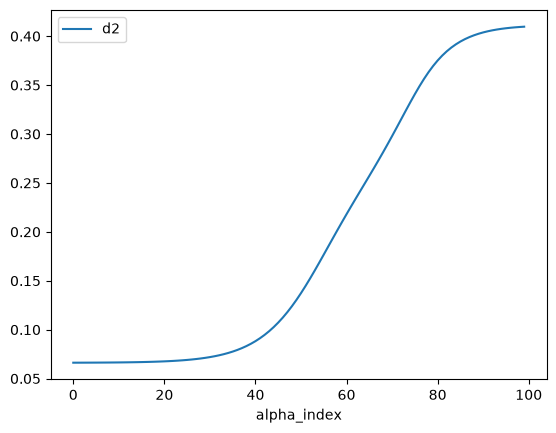

In [27]:
# fit the GLM
import glum as glm
from src.lib.glm import calc_path_stats

# when we fit a model, it automatically calculates MANY possible coefficient
# values by turning "off" coefficients.  We can see the most simple to the most
# complex model vs. the predictive performance. 
glmnet = glm.GeneralizedLinearRegressor(
    family="poisson",
    alpha_search=True,
    min_alpha_ratio=1e-6
)
glmnet.fit(
    X_mat_train,
    y = y_train,
    offset = offset_train
)

# print the curve showing how the model performs on the traing data as the
# model gets more complex (more coefficients).
df_path_stats_train = calc_path_stats(glmnet, X_mat_train, offset_train, y_train)
df_path_stats_train.plot("alpha_index", "d2")


<Axes: xlabel='alpha_index'>

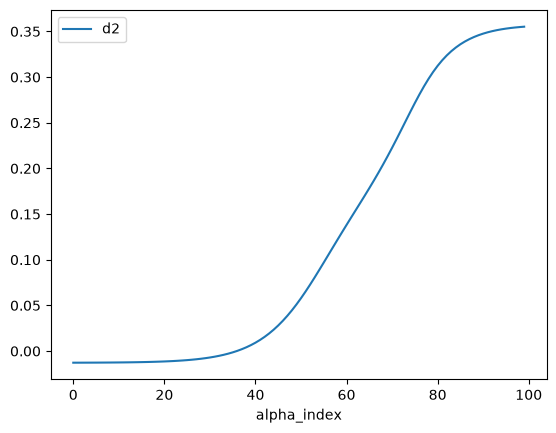

In [28]:
# by looking at the shape of this curve, we can tell when we are over-fitting.  
# if we see a decrease in the curve at higher alpha_index values, we are over-fitting.

# no signs of overfit!
df_path_stats_test = calc_path_stats(glmnet, X_mat_test, offset_test, y_test)
df_path_stats_test.plot("alpha_index", "d2")


### Run Predictions



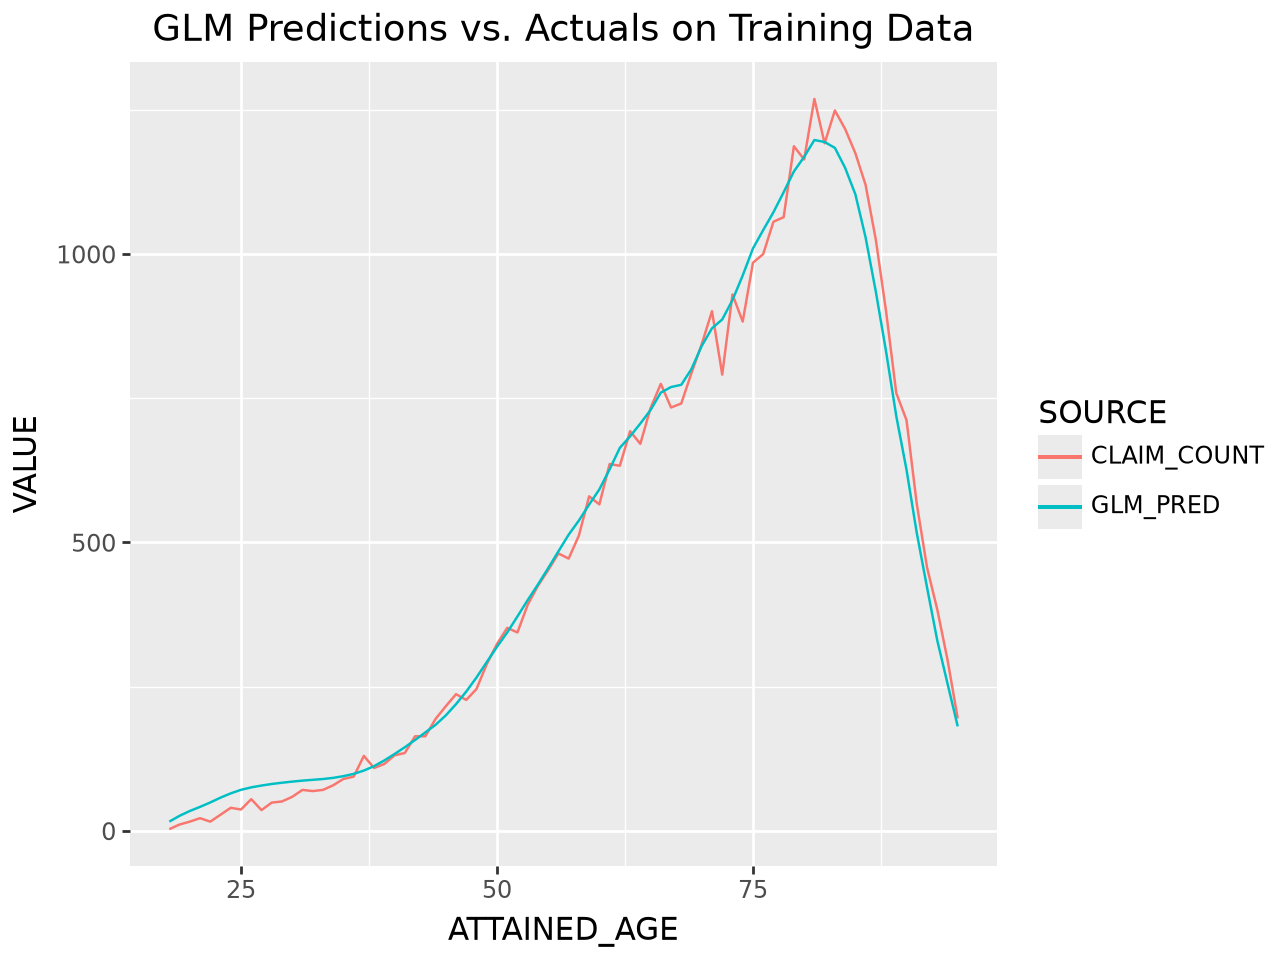

In [29]:
import plotnine as p9

df_train["GLM_PRED"] = glmnet.predict(X_mat_train, offset=offset_train) 

df_plot = df_train[["ATTAINED_AGE", "GLM_PRED", "CLAIM_COUNT"]].copy()
df_plot = df_plot.groupby("ATTAINED_AGE").agg({
    "GLM_PRED": "sum",
    "CLAIM_COUNT": "sum"
}).reset_index()
df_plot = df_plot.melt(id_vars="ATTAINED_AGE", value_vars=["GLM_PRED", "CLAIM_COUNT"], var_name="SOURCE", value_name="VALUE")

(
    p9.ggplot(df_plot, p9.aes(x="ATTAINED_AGE", y="VALUE", color="SOURCE")) +
    p9.geom_line() +
    p9.ggtitle("GLM Predictions vs. Actuals on Training Data")
)



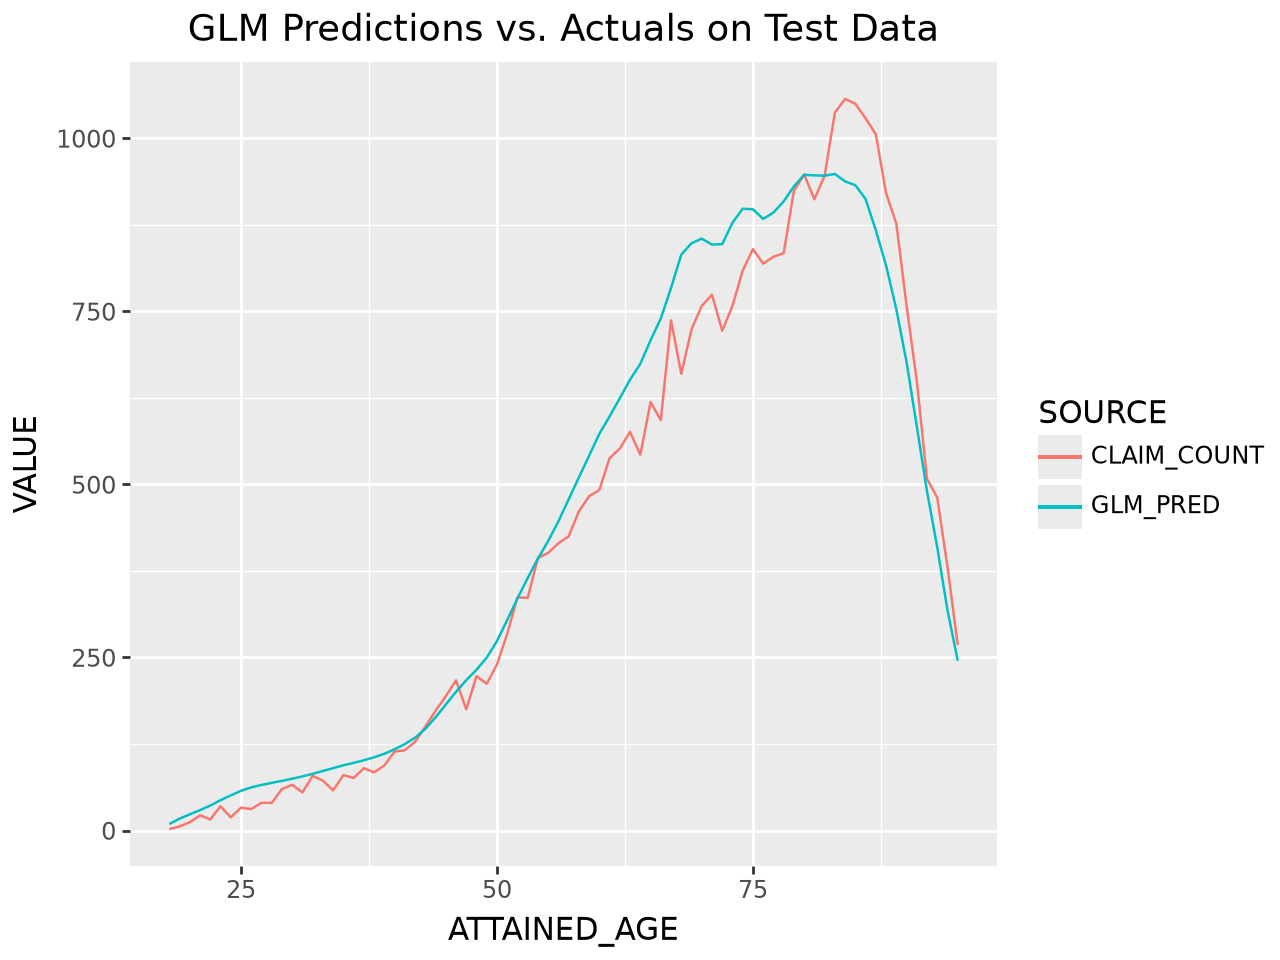

In [30]:
df_test["GLM_PRED"] = glmnet.predict(X_mat_test, offset=offset_test) 

df_plot = df_test[["ATTAINED_AGE", "GLM_PRED", "CLAIM_COUNT"]].copy()
df_plot = df_plot.groupby("ATTAINED_AGE").agg({
    "GLM_PRED": "sum",
    "CLAIM_COUNT": "sum"
}).reset_index()
df_plot = df_plot.melt(id_vars="ATTAINED_AGE", value_vars=["GLM_PRED", "CLAIM_COUNT"], var_name="SOURCE", value_name="VALUE")

(
    p9.ggplot(df_plot, p9.aes(x="ATTAINED_AGE", y="VALUE", color="SOURCE")) +
    p9.geom_line() +
    p9.ggtitle("GLM Predictions vs. Actuals on Test Data")
)

### Export Model Predictions

In [31]:
from src.lib.glm import PoissonGLMFactorAnalysis

factor_analysis = PoissonGLMFactorAnalysis(
    glmnet.coef_table(),
    model_spec)

# check that factors are mapped correctly
factors = factor_analysis.get_factor_analysis(df_train)

factors


[     factor term_group
 0  0.003397  intercept,
      ATTAINED_AGE  GENDER     factor             term_group
 0              18  FEMALE   0.352852  ATTAINED_AGE_x_GENDER
 1              18    MALE   0.295772  ATTAINED_AGE_x_GENDER
 2              19  FEMALE   0.316776  ATTAINED_AGE_x_GENDER
 3              19    MALE   0.270331  ATTAINED_AGE_x_GENDER
 4              20  FEMALE   0.284677  ATTAINED_AGE_x_GENDER
 ..            ...     ...        ...                    ...
 151            93    MALE  59.741251  ATTAINED_AGE_x_GENDER
 152            94  FEMALE  39.452012  ATTAINED_AGE_x_GENDER
 153            94    MALE  68.030817  ATTAINED_AGE_x_GENDER
 154            95  FEMALE  44.280232  ATTAINED_AGE_x_GENDER
 155            95    MALE  77.474695  ATTAINED_AGE_x_GENDER
 
 [156 rows x 4 columns]]

In [32]:
import os
import pandas as pd
from pathlib import Path

output_path = Path("../../factor_analysis_export.xlsx")
with pd.ExcelWriter(output_path) as writer:
    for i, df in enumerate(factors):
        sheet_name = f"factor_{i + 1}"
        df.to_excel(writer, sheet_name=sheet_name, index=False)

output_path

PosixPath('../../factor_analysis_export.xlsx')

### Applying a decision tree

Based on the decision tree, the next variable that we should add to the model is smoker status.

In [33]:
from src.lib.tree import PoissonDecisionTree

dtree = PoissonDecisionTree(
    offset_col="GLM_PRED",
    actual_col="CLAIM_COUNT",
    params={
        "min_child_weight": 0,
        "gamma": 3.0,
        "colsample_bytree": 1,
        "colsample_bylevel": 1
    }
)

x = (
    df_test
    .groupby([
        "SMOKER_STATUS", 
        "FACE_AMOUNT_GRP", 
        "DURATION",
        "PREFERRED_CLASS"])
    .agg({
        "CLAIM_COUNT":"sum",
        "GLM_PRED":"sum"
    })
).reset_index()

dtree.fit(x)
dtree.print_tree()


root: ae=0.9594   y=33479
  - SMOKER_STATUS < 0.5: ae=0.8894   y=29157
    - DURATION < 10.5: ae=0.5632   y=5082
      - FACE_AMOUNT_GRP < 1.5: ae=0.7067   y=1947
      - FACE_AMOUNT_GRP >= 1.5: ae=0.5001   y=3135
    - DURATION >= 10.5: ae=1.0133   y=24075
      - PREFERRED_CLASS < 0.5: ae=0.7874   y=6882
      - PREFERRED_CLASS >= 0.5: ae=1.1447   y=17193
  - SMOKER_STATUS >= 0.5: ae=2.0443   y=4322
    - FACE_AMOUNT_GRP < 2.5: ae=2.2244   y=2956
      - DURATION < 2.5: ae=1.6706   y=169
      - DURATION >= 2.5: ae=2.2700   y=2787
    - FACE_AMOUNT_GRP >= 2.5: ae=1.7396   y=1366
      - DURATION < 17.5: ae=1.4341   y=581
      - DURATION >= 17.5: ae=2.0652   y=785


#### Key-takeaways

 * The design matrix results from an R / Python formula.  We need to be cautious about the number of columns.

   * A regularized GLM (like `glmnet` or `glum`) helps us avoid overfitting with high dimensional design matricies.

 * Decision trees are powerful tools for identifying the next variable to add to our model and interactions. 

